# EDA: 3-year restaurant survival

Goal: identify which features affect `survived_3y`.
Assumption: the model predicts **before the restaurant opens**, so only features known at that point are analysed.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

## 1. Data loading and overview

In [5]:
df = pd.read_csv('archive-2/restaurant_survival.csv')

df.head()

,restaurant_id,cuisine,location_type,is_franchise,owner_experience_years,foot_traffic,competition_density,rent_to_revenue,starting_capital_months,labor_cost_ratio,price_tier,seats,menu_size,has_marketing,avg_review_rating,review_count,years_survived,failure_reason,survived_3y
0,RST000000,indian,tourist_area,1,3.8,2.92,4.98,0.083,7.1,0.368,2,29,12,1,3.38,55,1,poor_location,0
1,RST000001,italian,standalone,0,5.1,1.12,1.74,0.064,5.2,0.333,2,60,26,0,3.27,38,0,poor_food_reviews,0
2,RST000002,italian,downtown,1,5.2,7.81,4.85,0.072,4.1,0.301,1,178,59,1,3.34,149,3,survived,1
3,RST000003,mexican,standalone,0,9.1,5.57,5.18,0.106,1.9,0.303,2,172,20,0,4.69,85,0,undercapitalized,0
4,RST000004,indian,tourist_area,0,5.3,6.91,2.13,0.029,1.6,0.316,4,44,6,1,3.45,28,0,undercapitalized,0


In [6]:
df.shape

(45000, 19)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   restaurant_id            45000 non-null  str    
 1   cuisine                  45000 non-null  str    
 2   location_type            45000 non-null  str    
 3   is_franchise             45000 non-null  int64  
 4   owner_experience_years   45000 non-null  float64
 5   foot_traffic             45000 non-null  float64
 6   competition_density      45000 non-null  float64
 7   rent_to_revenue          45000 non-null  float64
 8   starting_capital_months  45000 non-null  float64
 9   labor_cost_ratio         45000 non-null  float64
 10  price_tier               45000 non-null  int64  
 11  seats                    45000 non-null  int64  
 12  menu_size                45000 non-null  int64  
 13  has_marketing            45000 non-null  int64  
 14  avg_review_rating        45000 no

In [8]:
df.describe(include='all').T.round(2)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
restaurant_id,45000,45000,RST000000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cuisine,45000,9,american,7115,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location_type,45000,5,suburb_strip,12638,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_franchise,45000.0,NaN,NaN,NaN,0.241111,0.427762,0.0,0.0,0.0,0.0,1.0
owner_experience_years,45000.0,NaN,NaN,NaN,7.204918,5.343871,0.0,3.3,5.9,9.8,35.0
foot_traffic,45000.0,NaN,NaN,NaN,5.346598,2.232485,0.0,3.8,5.36,6.9,10.0
competition_density,45000.0,NaN,NaN,NaN,5.269486,2.187399,0.0,3.77,5.27,6.77,10.0
rent_to_revenue,45000.0,NaN,NaN,NaN,0.104807,0.049453,0.02,0.069,0.103,0.139,0.32
starting_capital_months,45000.0,NaN,NaN,NaN,4.213404,3.225952,0.5,1.9,3.4,5.6,36.0
labor_cost_ratio,45000.0,NaN,NaN,NaN,0.299834,0.050016,0.15,0.266,0.3,0.334,0.488


## 2. Data quality

In [10]:
miss = df.isna().mean().sort_values(ascending=False)
miss[miss > 0].round(3)

Series([], dtype: float64)

In [11]:
print('Unique records in dataset:', df['restaurant_id'].is_unique)
print('Number of duplicated records:', df.duplicated().sum())

Unique records in dataset: True
Number of duplicated records: 0


No missing values or duplicates, and every `restaurant_id` is unique. The data needs no cleaning.

## 3. Target variable

Survived 3 years rate: 50.6%


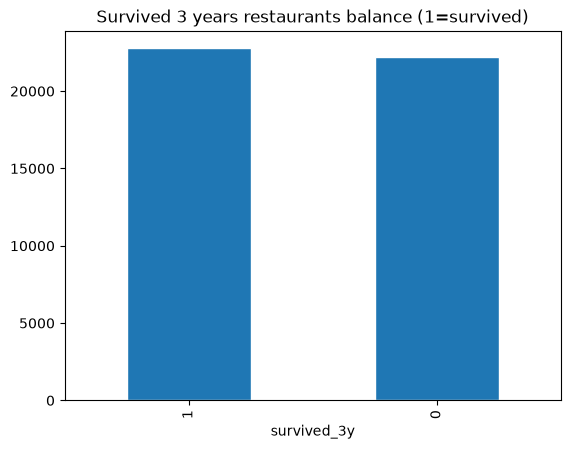

In [14]:
target_rate = df['survived_3y'].mean()
print(f'Survived 3 years rate: {target_rate:.1%}')
df['survived_3y'].value_counts().plot(kind='bar', edgecolor='white',
                                  title='Survived 3 years restaurants balance (1=survived)')
plt.show()

The classes are balanced (50.6% survived), so accuracy is a reasonable metric and no resampling is needed.

## 4. Feature distributions

Columns known only after opening are skipped: `avg_review_rating`, `review_count`, `years_survived`, `failure_reason`. The last two directly reveal the target.
`rent_to_revenue` and `labor_cost_ratio` are treated as planned values from the business plan.

In [17]:
numerical_cols = [
    "owner_experience_years", "foot_traffic", "competition_density", "rent_to_revenue", "starting_capital_months",
    "labor_cost_ratio", "seats", "menu_size"
]
df[numerical_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
owner_experience_years,45000.0,7.20,5.34,0.00,3.30,5.90,9.80,35.00
foot_traffic,45000.0,5.35,2.23,0.00,3.80,5.36,6.90,10.00
competition_density,45000.0,5.27,2.19,0.00,3.77,5.27,6.77,10.00
rent_to_revenue,45000.0,0.10,0.05,0.02,0.07,0.10,0.14,0.32
starting_capital_months,45000.0,4.21,3.23,0.50,1.90,3.40,5.60,36.00
labor_cost_ratio,45000.0,0.30,0.05,0.15,0.27,0.30,0.33,0.49
seats,45000.0,57.30,38.50,12.00,29.00,48.00,76.00,300.00
menu_size,45000.0,40.20,17.45,6.00,28.00,40.00,52.00,110.00


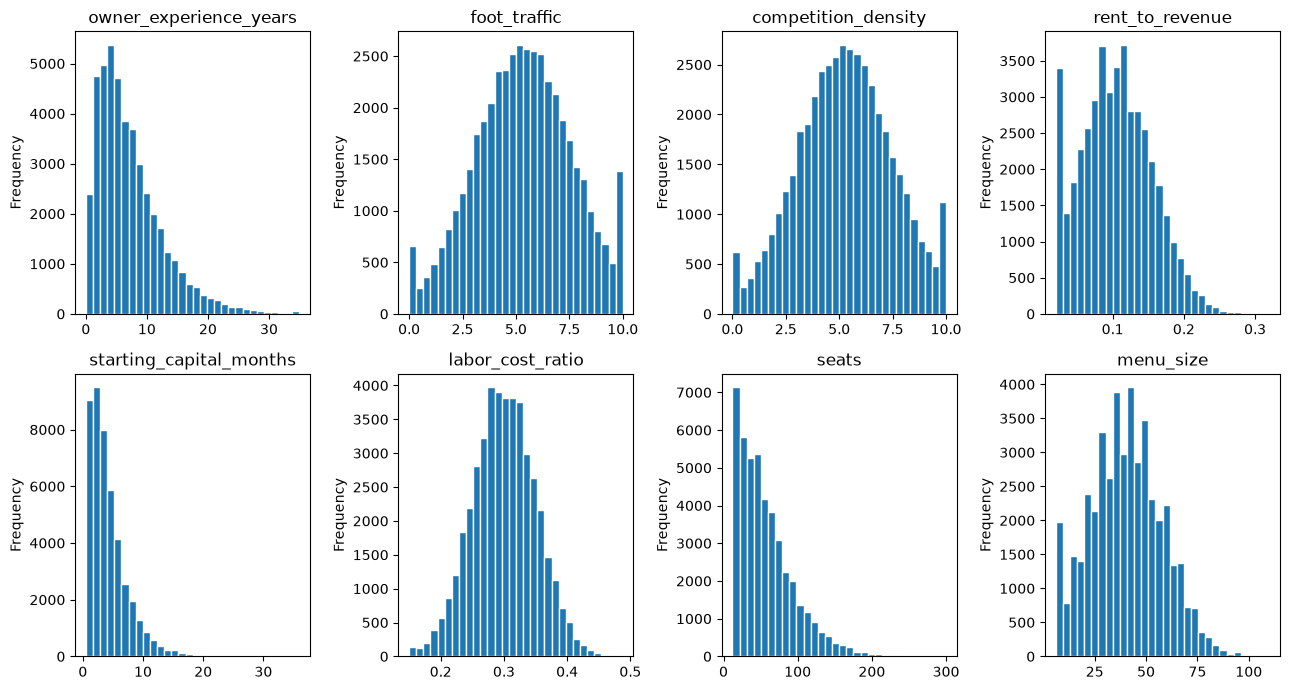

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(13, 7))
for ax, col in zip(axes.ravel(), numerical_cols):
    df[col].plot(kind='hist', bins=30, ax=ax, edgecolor='white')
    ax.set_title(col)
fig.tight_layout(); plt.show()

`owner_experience_years`, `starting_capital_months` and `seats` are right-skewed. Spikes at the range limits (e.g. 0 and 10 in `foot_traffic`) indicate value clipping, typical of synthetic data.

In [20]:
categorical_columns = ["cuisine", "location_type",]

for col in categorical_columns:
    print(f"--- {col}")
    print(df[col].value_counts(normalize=True).round(3).to_string(), "\n")

--- cuisine
cuisine
american       0.158
fast_casual    0.141
italian        0.129
mexican        0.120
chinese        0.111
cafe           0.111
fine_dining    0.080
japanese       0.080
indian         0.070 

--- location_type
location_type
suburb_strip      0.281
downtown          0.259
standalone        0.178
tourist_area      0.142
mall_foodcourt    0.140 



Categories are fairly evenly distributed, and none is rare enough to merge with others.

## 5. Features vs survival

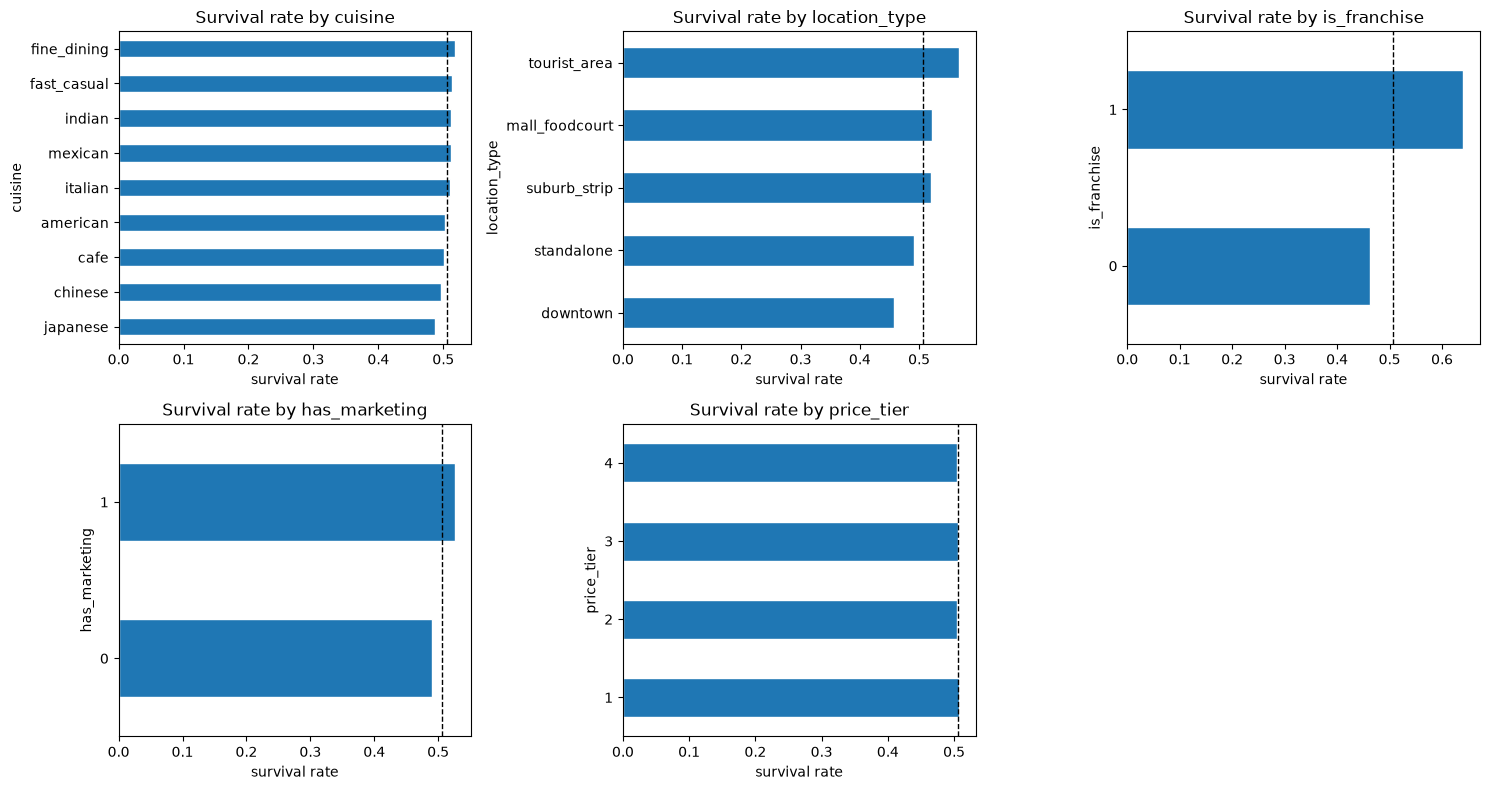

In [23]:
group_cols = ['cuisine', 'location_type', 'is_franchise', 'has_marketing', 'price_tier']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), group_cols):
    rate = df.groupby(col)['survived_3y'].mean()
    rate = rate.sort_values() if df[col].dtype != 'int64' else rate.sort_index()
    rate.plot.barh(ax=ax, edgecolor='white')
    ax.axvline(target_rate, color='black', linestyle='--', linewidth=1)
    ax.set_title(f'Survival rate by {col}')
    ax.set_xlabel('survival rate')
axes.ravel()[-1].axis('off')
fig.tight_layout(); plt.show()

`is_franchise` has the strongest effect (about 64% vs 46%). Among locations, `tourist_area` performs best and `downtown` worst. `cuisine` and `price_tier` barely differentiate survival.

In [25]:
df.groupby('location_type')[['rent_to_revenue', 'competition_density', 'foot_traffic']].mean().round(3)

,rent_to_revenue,competition_density,foot_traffic
location_type,,,
downtown,0.118,5.986,6.141
mall_foodcourt,0.101,5.022,5.012
standalone,0.100,4.992,4.547
suburb_strip,0.099,5.011,4.969
tourist_area,0.100,5.070,5.981


`downtown` has higher rent and more competition, which explains its lower survival despite high foot traffic. The location effect therefore comes mainly from the numerical features.

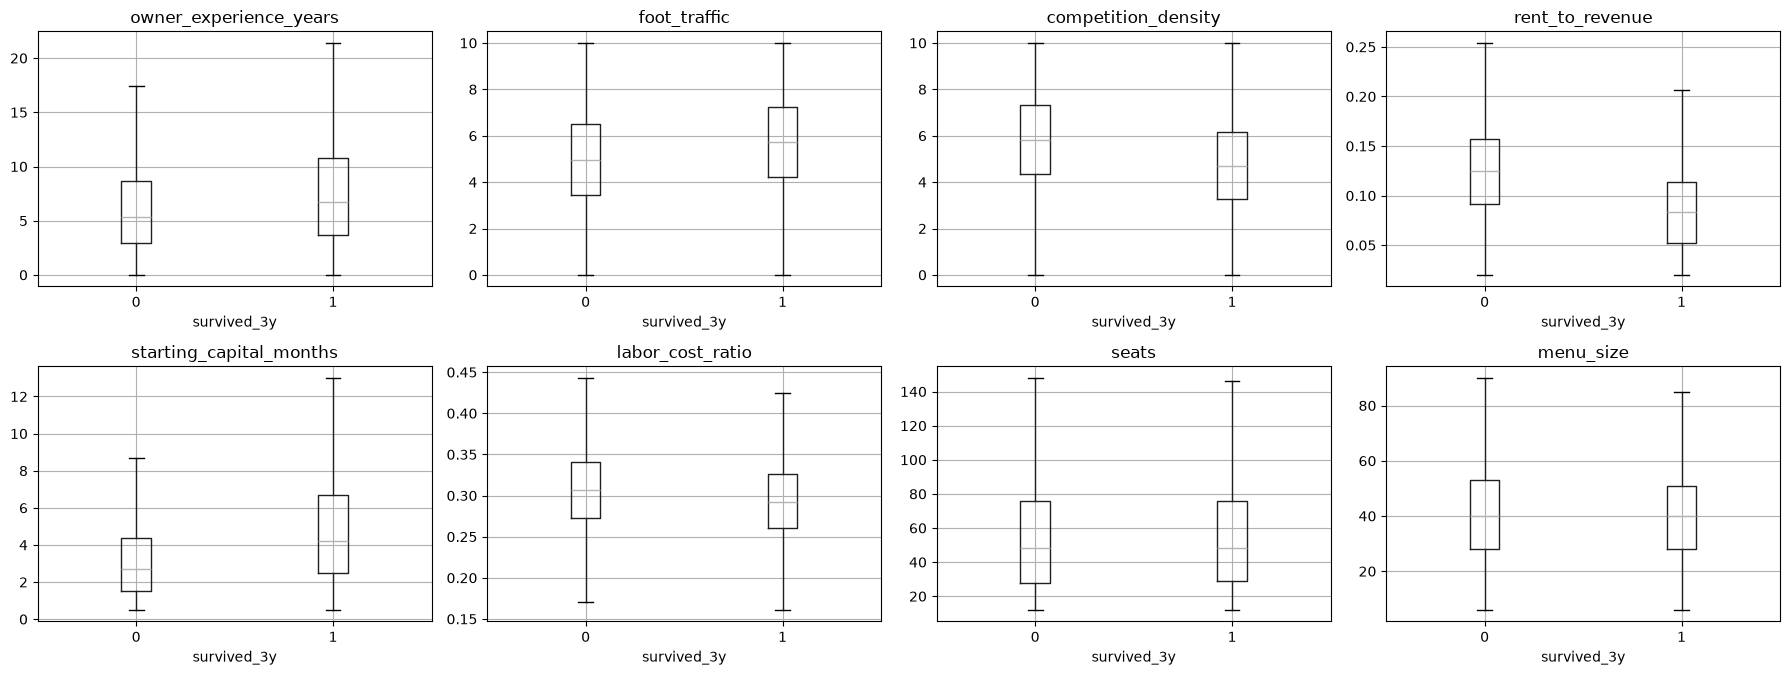

In [27]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.ravel(), numerical_cols):
    df.boxplot(column=col, by='survived_3y', ax=ax, showfliers=False)
    ax.set_title(col); ax.set_xlabel('survived_3y')
fig.suptitle('')
fig.tight_layout(); plt.show()

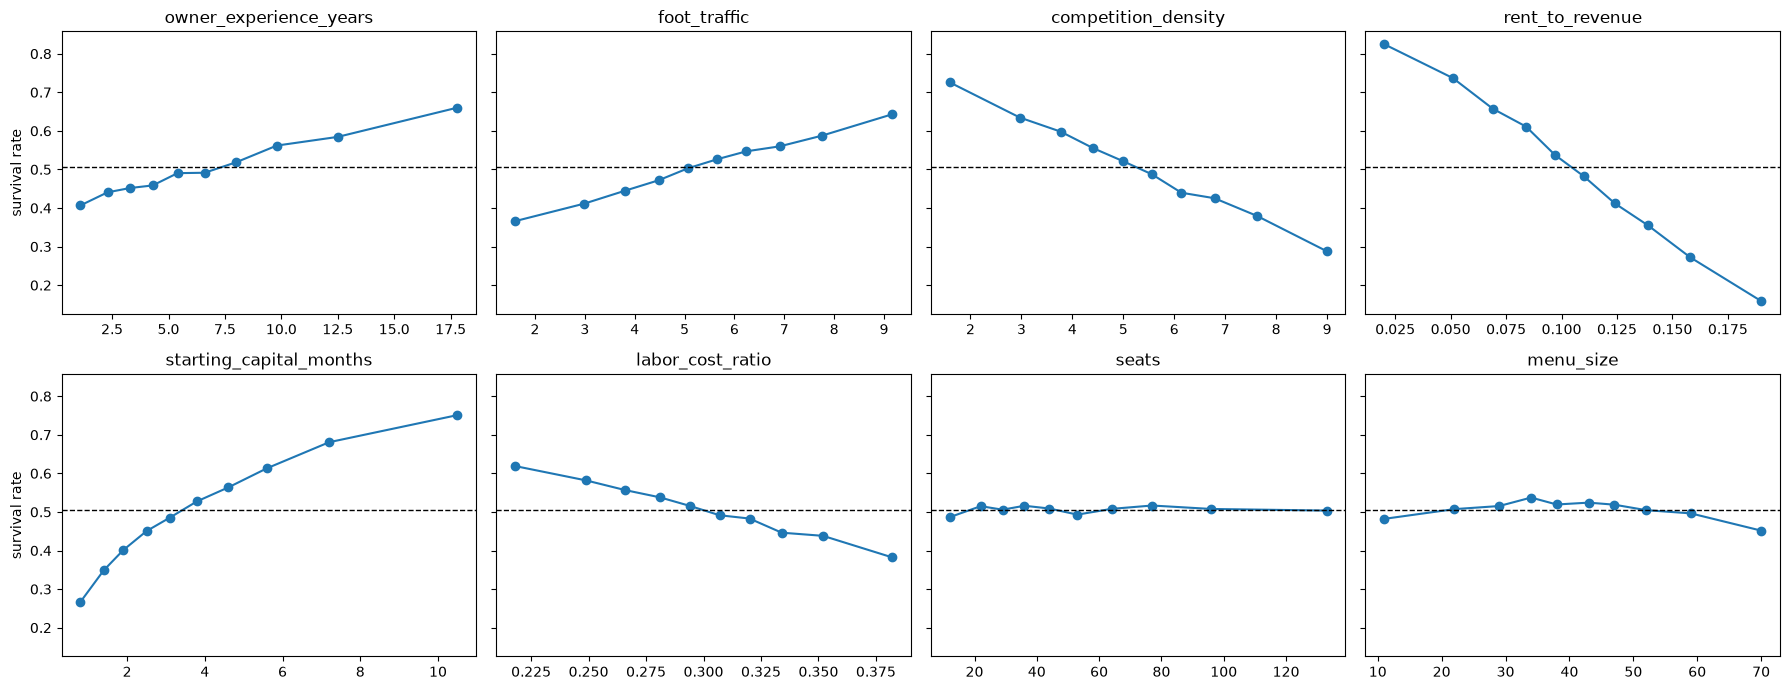

In [28]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharey=True)
for ax, col in zip(axes.ravel(), numerical_cols):
    bins = pd.qcut(df[col], q=10, duplicates='drop')
    g = df.groupby(bins, observed=True).agg(x=(col, 'median'), rate=('survived_3y', 'mean'))
    ax.plot(g['x'], g['rate'], marker='o')
    ax.axhline(target_rate, color='black', linestyle='--', linewidth=1)
    ax.set_title(col)
axes[0, 0].set_ylabel('survival rate'); axes[1, 0].set_ylabel('survival rate')
fig.tight_layout(); plt.show()

The strongest effects come from `rent_to_revenue` and `competition_density` (negative) and from `starting_capital_months` and `foot_traffic` (positive). Capital shows diminishing returns, `menu_size` a slight inverted U shape, and `seats` has no effect.

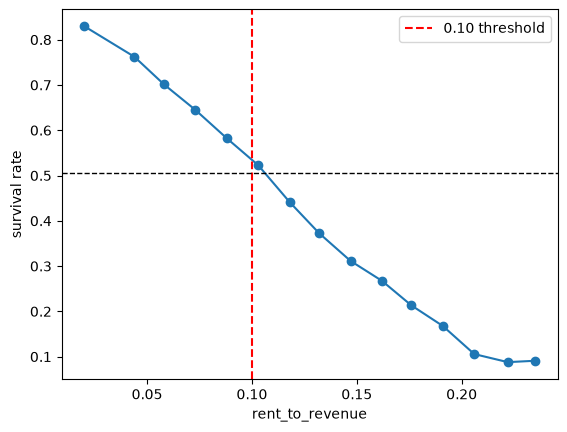

                     mean  count
rent_to_revenue                 
False            0.681639  21529
True             0.344638  23471


In [30]:
bins = pd.cut(df['rent_to_revenue'], bins=20)
g = df.groupby(bins, observed=True).agg(x=('rent_to_revenue', 'median'),
                                        rate=('survived_3y', 'mean'), n=('survived_3y', 'size'))
g = g[g['n'] >= 100]

plt.plot(g['x'], g['rate'], marker='o')
plt.axvline(0.10, color='red', linestyle='--', label='0.10 threshold')
plt.axhline(target_rate, color='black', linestyle='--', linewidth=1)
plt.xlabel('rent_to_revenue'); plt.ylabel('survival rate'); plt.legend()
plt.show()

print(df.groupby(df['rent_to_revenue'] > 0.10)['survived_3y'].agg(['mean', 'count']))

There is no sharp threshold at 0.10. Survival declines smoothly, and 0.10 is simply where it crosses the average.

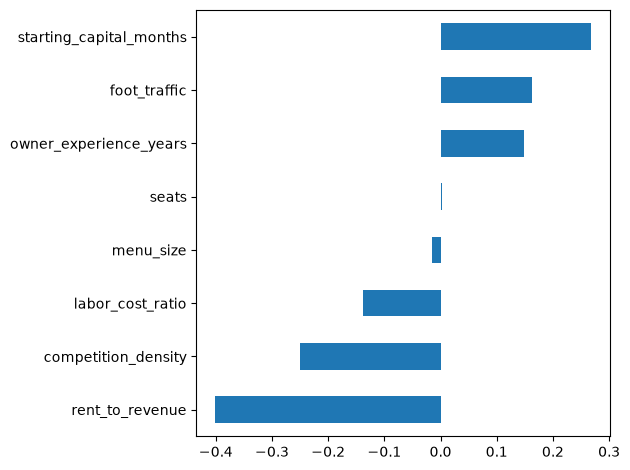

rent_to_revenue           -0.40
competition_density       -0.25
labor_cost_ratio          -0.14
menu_size                 -0.02
seats                      0.00
owner_experience_years     0.15
foot_traffic               0.16
starting_capital_months    0.27
Name: survived_3y, dtype: float64

In [32]:
corr_cols = numerical_cols + ['survived_3y']
corr = df[corr_cols].corr()['survived_3y'].drop('survived_3y')
corr.sort_values().plot.barh()
plt.tight_layout(); plt.show()
corr.sort_values().round(2)

The correlations confirm the ranking from the plots: `rent_to_revenue` (-0.40) is the strongest predictor, followed by `starting_capital_months` (+0.27) and `competition_density` (-0.25). `seats` and `menu_size` are close to zero.

## 6. Summary

- The data is clean and balanced.
- Key features: `rent_to_revenue`, `starting_capital_months`, `competition_density`, `foot_traffic`, `is_franchise`.
- Moderate effect: `owner_experience_years`, `labor_cost_ratio`, `location_type`, `has_marketing`.
- Weak or no effect: `seats`, `price_tier`, `cuisine`.
- For modelling: one-hot encoding for `cuisine` and `location_type`
- Excluded: `restaurant_id` and columns known only after opening.
